# Évaluation sommative 2 : Création des pipelines
## Prédiction des annulations de réservations hôtelières (Hotel Booking Demand)

**Cours :** Intelligence artificielle appliquée au prétraitement des données (030513 IFM), automne 2026  
**Professeure :** Nadjate Saïdani  
**Étudiant :** Yacine Lezoul  
**Date :** 11 novembre 2026

---

### Objectif
Concevoir un pipeline scikit-learn complet qui enchaîne le prétraitement des données, des transformations personnalisées, la sélection des caractéristiques et un modèle de classification, afin de prédire si une réservation sera annulée (`is_canceled`).

### Organisation du projet
Le code est rangé dans des modules Python (`src/`), et ce notebook sert à **exécuter, présenter et interpréter** chaque étape. Cette séparation rend le code réutilisable (script d'entraînement, application Streamlit, tests unitaires) et garde le notebook lisible.

| Module | Rôle |
|---|---|
| `src/config.py` | chemins, listes de colonnes, paramètres de reproductibilité |
| `src/data_loader.py` | chargement, audit de qualité, nettoyage, séparation 80/20 |
| `src/transformers.py` | transformateurs personnalisés (`TransformerMixin`) |
| `src/preprocessing.py` | pipelines par type de variable et `ColumnTransformer` |
| `src/feature_selection.py` | sélection des caractéristiques (`SelectFromModel`) |
| `src/model.py` | pipeline complet, comparaison, optimisation, sauvegarde |
| `src/evaluation.py` | métriques, graphiques, importance par permutation |
| `src/prescriptive.py` | seuil optimal, actions recommandées, surréservation |

### Plan
1. Exploration et préparation des données
2. Construction des pipelines de prétraitement
3. Création de transformateurs personnalisés
4. Sélection des caractéristiques
5. Construction et évaluation du modèle prédictif
6. Ouverture : de la prédiction à la décision (analyse prescriptive)

In [1]:
# Configuration de l'environnement
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config

# Les transformateurs renvoient des DataFrame : les noms de colonnes restent visibles à chaque étape
set_config(transform_output="pandas", display="diagram")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))
sns.set_theme(style="whitegrid", palette="deep")

from src import config
from src import data_loader as dl

---
# Partie 1 : Exploration et préparation des données

## 1.1 Importation et structure générale
Les valeurs `NULL` des colonnes `agent` et `company` sont lues comme des valeurs manquantes.

In [2]:
df_raw = dl.load_raw_data()
print(f"Dimensions : {df_raw.shape[0]:,} lignes x {df_raw.shape[1]} colonnes".replace(",", " "))
df_raw.head()

Dimensions : 119 390 lignes x 32 colonnes


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119 390.000,0.370,0.483,0.000,0.000,0.000,1.000,1.000
lead_time,119 390.000,104.011,106.863,0.000,18.000,69.000,160.000,737.000
arrival_date_year,119 390.000,2 016.157,0.707,2 015.000,2 016.000,2 016.000,2 017.000,2 017.000
arrival_date_week_number,119 390.000,27.165,13.605,1.000,16.000,28.000,38.000,53.000
arrival_date_day_of_month,119 390.000,15.798,8.781,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,119 390.000,0.928,0.999,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,119 390.000,2.500,1.908,0.000,1.000,2.000,3.000,50.000
adults,119 390.000,1.856,0.579,0.000,2.000,2.000,2.000,55.000
children,119 386.000,0.104,0.399,0.000,0.000,0.000,0.000,10.000
babies,119 390.000,0.008,0.097,0.000,0.000,0.000,0.000,10.000


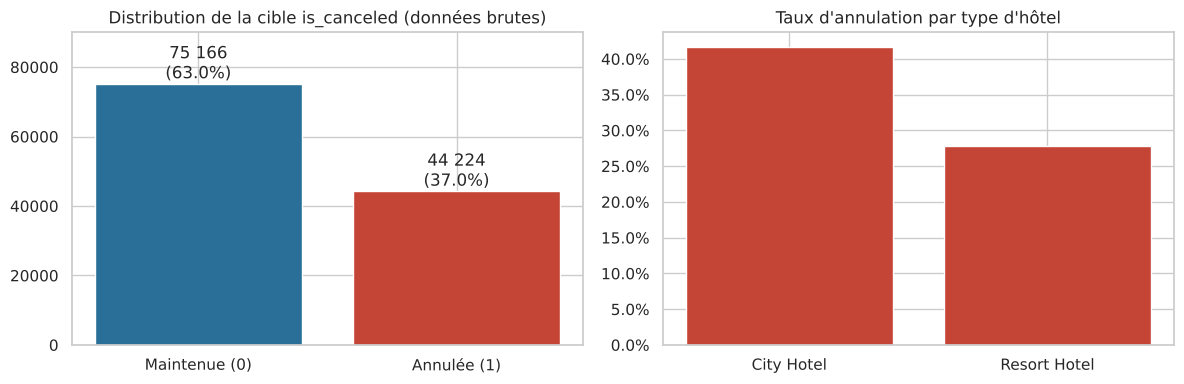

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
counts = df_raw[config.TARGET].value_counts().sort_index()
ax[0].bar(["Maintenue (0)", "Annulée (1)"], counts.values, color=["#2a6f97", "#c44536"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}\n({v / counts.sum():.1%})".replace(",", " "), ha="center", va="bottom")
ax[0].set_title("Distribution de la cible is_canceled (données brutes)")
ax[0].set_ylim(0, counts.max() * 1.2)
rate = df_raw.groupby("hotel")[config.TARGET].mean()
ax[1].bar(rate.index, rate.values, color="#c44536")
ax[1].set_title("Taux d'annulation par type d'hôtel")
ax[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

**Interprétation :** le jeu brut compte 119 390 réservations et 32 colonnes (20 numériques, 12 textuelles). La cible est **déséquilibrée sans être extrême** : 37 % d'annulations dans les données brutes. Le City Hotel annule nettement plus (41,7 %) que le Resort Hotel (27,8 %) ; le type d'hôtel sera donc une variable explicative utile.

## 1.2 Variables numériques, catégorielles et problèmes de qualité

### Typologie des variables

In [6]:
num_cols = df_raw.select_dtypes(include="number").columns.drop(config.TARGET).tolist()
cat_cols = df_raw.select_dtypes(exclude="number").columns.tolist()
print(f"Variables numériques ({len(num_cols)}) :", num_cols, "\n")
print(f"Variables catégorielles ({len(cat_cols)}) :", cat_cols)

Variables numériques (19) : ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests'] 

Variables catégorielles (12) : ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


**Attention aux faux numériques :** `agent` et `company` sont stockés comme des nombres mais ce sont des **identifiants** (aucun ordre, aucune distance). `is_repeated_guest` est un indicateur binaire. Les colonnes `arrival_date_*` décrivent le calendrier. Le type informatique ne suffit donc pas : chaque variable reçoit un traitement selon sa **nature** (Partie 2).

### Valeurs manquantes et cardinalité

In [7]:
dl.quality_report(df_raw).head(12)

,type,manquants,manquants_%,valeurs_uniques
company,float64,112593,94.310,352
agent,float64,16340,13.690,333
country,str,488,0.410,177
hotel,str,0,0.000,2
arrival_date_month,str,0,0.000,12
arrival_date_week_number,int64,0,0.000,53
lead_time,int64,0,0.000,479
is_canceled,int64,0,0.000,2
stays_in_weekend_nights,int64,0,0.000,17
stays_in_week_nights,int64,0,0.000,35


### Anomalies détectées

In [8]:
dl.quality_issues(df_raw).to_frame()

,nombre de lignes
lignes en double,31994
"réservations sans aucun client (0 adulte, 0 enfant, 0 bébé)",180
adr négatif,1
adr aberrant (> 1 000),1
séjours de 0 nuit,715
meal = 'Undefined' (équivaut à SC selon la fiche),1169
market_segment = 'Undefined',2
distribution_channel = 'Undefined',5
children manquant,4
country manquant,488


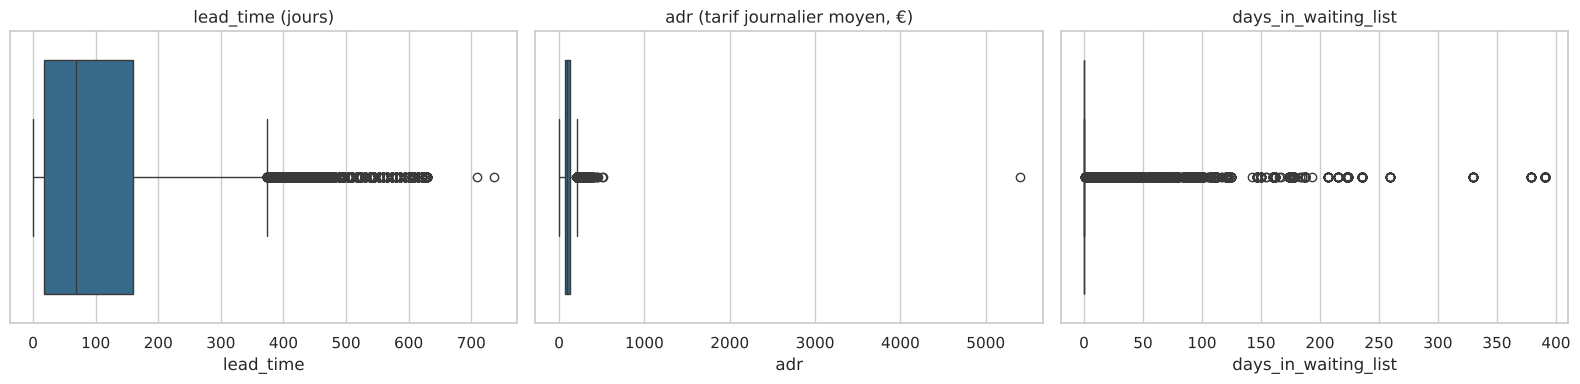

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=df_raw["lead_time"], ax=axes[0], color="#2a6f97"); axes[0].set_title("lead_time (jours)")
sns.boxplot(x=df_raw["adr"], ax=axes[1], color="#2a6f97"); axes[1].set_title("adr (tarif journalier moyen, €)")
sns.boxplot(x=df_raw["days_in_waiting_list"], ax=axes[2], color="#2a6f97"); axes[2].set_title("days_in_waiting_list")
plt.tight_layout(); plt.show()

In [10]:
top_countries = df_raw["country"].value_counts()
print(f"Nombre de pays : {top_countries.size}")
print(f"Pays représentant moins de 0,5 % des réservations : {(top_countries / len(df_raw) < 0.005).sum()}")
top_countries.head(10).to_frame("réservations")

Nombre de pays : 177
Pays représentant moins de 0,5 % des réservations : 157


,réservations
country,
PRT,48590
GBR,12129
FRA,10415
ESP,8568
DEU,7287
ITA,3766
IRL,3375
BEL,2342
BRA,2224


**Interprétation :** plusieurs problèmes de qualité doivent être traités :

- **Valeurs manquantes** : `company` (94 %) et `agent` (14 %) ne sont pas de vraies absences, elles signifient « pas d'entreprise » et « pas d'agence ». `country` (488 lignes) et `children` (4 lignes) sont de vraies données manquantes.
- **Doublons** : 31 994 lignes identiques (27 %). Sans identifiant de réservation, on ne peut pas distinguer une vraie réservation de groupe d'une copie ; les garder ferait apparaître des lignes identiques dans l'entraînement et le test.
- **Valeurs impossibles** : 180 réservations sans aucun client, un tarif négatif, un tarif de 5 400 €.
- **Modalités ambiguës** : `meal = Undefined` (équivalent de SC selon la fiche), `market_segment` et `distribution_channel = Undefined`.
- **Valeurs extrêmes et asymétrie** : `lead_time` jusqu'à 737 jours, `days_in_waiting_list` jusqu'à 391 jours, `adr` avec une longue queue.
- **Forte cardinalité** : 177 pays dont 157 pèsent chacun moins de 0,5 % des réservations.

### Détection d'une fuite de données (data leakage)
Certaines colonnes ne sont connues **qu'après** l'issue de la réservation. Le tableau ci-dessous croise `reservation_status` avec la cible.

In [11]:
pd.crosstab(df_raw["reservation_status"], df_raw[config.TARGET], margins=True, margins_name="Total")

is_canceled,0,1,Total
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
Total,75166,44224,119390


In [12]:
# assigned_room_type : la chambre attribuée à l'arrivée diffère souvent de la chambre réservée
diff_room = df_raw["reserved_room_type"] != df_raw["assigned_room_type"]
df_raw.groupby(diff_room)[config.TARGET].mean().rename(index={False: "même chambre", True: "chambre différente"}).to_frame("taux d'annulation")

,taux d'annulation
même chambre,0.416
chambre différente,0.054


**Interprétation :** `reservation_status` reproduit exactement la cible (Canceled et No-Show = 1, Check-Out = 0) : le garder donnerait un modèle « parfait » mais inutilisable, car ce statut n'existe qu'après coup. De même, une chambre attribuée différente de la chambre réservée s'accompagne de seulement 5,4 % d'annulations contre 41,6 % sinon : la chambre est attribuée à l'arrivée du client, ce qui révèle qu'il est venu. `reservation_status`, `reservation_status_date` et `assigned_room_type` sont donc retirées.

### Relations exploratoires avec la cible

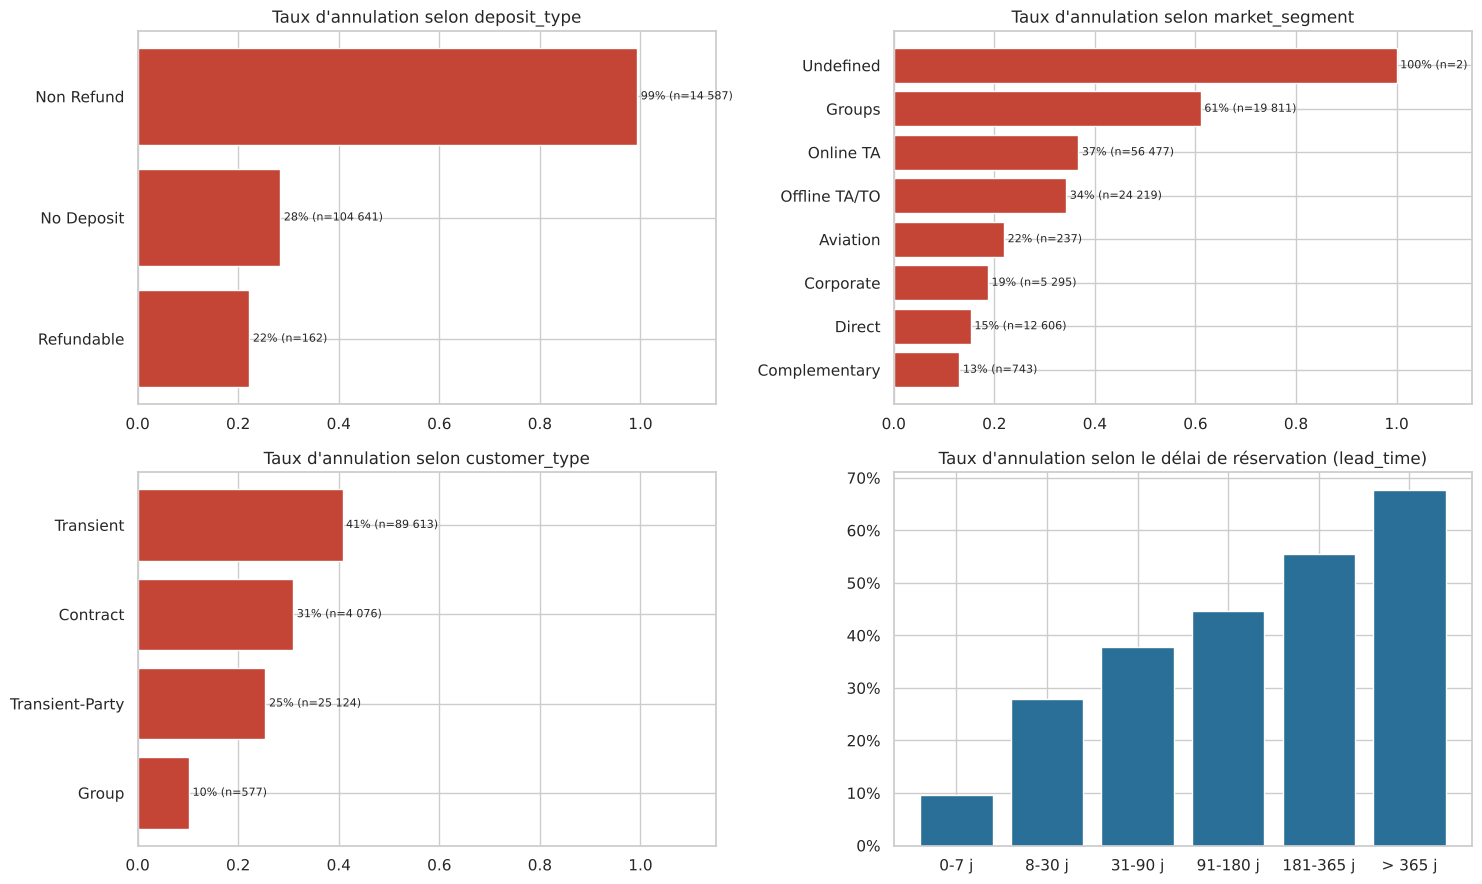

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat[:3], ["deposit_type", "market_segment", "customer_type"]):
    r = df_raw.groupby(col)[config.TARGET].agg(["mean", "size"]).sort_values("mean")
    ax.barh(r.index, r["mean"], color="#c44536")
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(m, i, f" {m:.0%} (n={n:,})".replace(",", " "), va="center", fontsize=8)
    ax.set_title(f"Taux d'annulation selon {col}")
    ax.set_xlim(0, 1.15)
bins = [-1, 7, 30, 90, 180, 365, 800]
labels = ["0-7 j", "8-30 j", "31-90 j", "91-180 j", "181-365 j", "> 365 j"]
r = df_raw.groupby(pd.cut(df_raw["lead_time"], bins=bins, labels=labels), observed=True)[config.TARGET].mean()
axes[1, 1].bar(r.index.astype(str), r.values, color="#2a6f97")
axes[1, 1].set_title("Taux d'annulation selon le délai de réservation (lead_time)")
axes[1, 1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "exploration_taux_annulation.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation :**

- **Délai de réservation** : relation très nette et croissante, de 10 % d'annulations pour une réservation à moins d'une semaine à 68 % au-delà d'un an. Plus le client réserve tôt, plus ses projets ont le temps de changer.
- **Segment de marché** : les groupes (61 %) et les agences en ligne (37 %) annulent beaucoup plus que la clientèle directe (15 %) ou d'entreprise (19 %).
- **Type de dépôt** : les réservations non remboursables annulent à 99 %, ce qui est contre-intuitif. C'est une particularité connue de ce jeu (probablement des blocs de réservations de groupes ou d'agences libérés en masse). La variable est conservée car elle est connue au moment de la réservation, mais ce comportement est spécifique à ces deux hôtels.
- **Type de client** : les clients individuels (*Transient*, 41 %) annulent plus que les groupes sous contrat.

### Nettoyage de base
Seules des opérations **ligne par ligne**, sans statistique apprise, sont faites ici (avant la séparation). Tout ce qui s'apprend sur les données (médianes, bornes d'écrêtage, modalités fréquentes) est fait dans le pipeline, uniquement sur l'entraînement.

| Décision | Raison |
|---|---|
| Retrait de `reservation_status`, `reservation_status_date`, `assigned_room_type` | fuite de données (information postérieure à la décision) |
| Suppression des doublons exacts | sans identifiant de réservation, des copies identiques se retrouveraient à la fois dans l'entraînement et le test, ce qui gonflerait les scores |
| Suppression des réservations sans client | réservation impossible (0 adulte, 0 enfant, 0 bébé) |
| Suppression de `adr` < 0 et `adr` > 5 000 | tarifs impossibles (erreurs de saisie isolées) |

In [14]:
df = dl.clean_data(df_raw)
print(f"\nTaux d'annulation après nettoyage : {df[config.TARGET].mean():.1%}")

Lignes initiales                     : 119 390
Doublons supprimés                   :  33 241
Réservations sans client supprimées  :     165
Tarifs impossibles supprimés         :       2
Lignes finales                       :  85 982

Taux d'annulation après nettoyage : 27.6%


**Interprétation :** après nettoyage, il reste **85 982 réservations**. Le nombre de doublons supprimés (33 241) est légèrement supérieur au décompte initial car les colonnes de fuite ont été retirées d'abord : des lignes qui ne différaient que par la date de statut deviennent identiques. Le taux d'annulation passe de 37 % à **27,6 %** : les doublons étaient surtout des annulations (blocs de réservations de groupes annulés ensemble). Sans ce nettoyage, le modèle aurait appris sur une image déformée du problème.

## 1.3 Variables explicatives et variable cible
- **Cible `y`** : `is_canceled` (1 = annulée, 0 = maintenue). Problème de **classification binaire**.
- **Variables explicatives `X`** : les informations disponibles **au moment de la réservation**.

Variables exclues de `X` en plus des colonnes de fuite :
- `arrival_date_year` (2015 à 2017) : le modèle servira sur des années futures qu'il n'a jamais vues ; l'année n'apporterait qu'un effet propre à l'historique.

In [15]:
X, y = dl.split_features_target(df)
print(f"X : {X.shape}, y : {y.shape}")
excluded = sorted(set(df.columns) - set(X.columns) - {config.TARGET})
print("Colonnes du DataFrame nettoyé non utilisées comme variables explicatives :", excluded)
X.head(3)

X : (85982, 27), y : (85982,)
Colonnes du DataFrame nettoyé non utilisées comme variables explicatives : ['arrival_date_year']


,hotel,lead_time,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,342,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0
1,Resort Hotel,737,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0
2,Resort Hotel,7,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0


## 1.4 Séparation entraînement (80 %) / test (20 %)
La séparation est **stratifiée** sur la cible pour garder le même taux d'annulation dans les deux ensembles, et `random_state` est fixé pour la reproductibilité. L'ensemble de test n'est plus touché jusqu'à l'évaluation finale.

In [16]:
X_train, X_test, y_train, y_test = dl.train_test_data(X, y)
pd.DataFrame(
    {
        "lignes": [len(X_train), len(X_test)],
        "part": [len(X_train) / len(X), len(X_test) / len(X)],
        "taux d'annulation": [y_train.mean(), y_test.mean()],
    },
    index=["entraînement", "test"],
)

,lignes,part,taux d'annulation
entraînement,68785,0.800,0.276
test,17197,0.200,0.276


---
# Partie 2 : Construction des pipelines de prétraitement

## 2.1 Traitements retenus par type de variable

| Groupe | Variables | Traitements | Justification |
|---|---|---|---|
| **Continues asymétriques** | `lead_time`, `adr`, nuits de semaine et de fin de semaine, `total_nights`, `adr_per_person` | médiane, écrêtage 1 % / 99 %, standardisation | distributions très asymétriques avec valeurs extrêmes (737 jours de délai, 50 nuits) ; la médiane résiste aux extrêmes ; l'écrêtage évite qu'ils dominent la standardisation |
| **Discrètes** | comptages (clients, annulations passées, modifications, demandes, jours en liste d'attente) et calendrier | médiane, standardisation | pas d'écrêtage : le 99e centile vaut souvent 0 ou 1 (plus de 99 % des réservations n'ont aucun jour d'attente), l'écrêtage effacerait des profils rares mais informatifs |
| **Binaires** | `is_repeated_guest`, `has_children`, `has_agent`, `has_company` | valeur la plus fréquente | déjà en 0/1, la mise à l'échelle n'apporte rien |
| **Catégorielles** | `hotel`, mois, saison, `meal`, `country`, segments, canal, type de chambre, dépôt, type de client | constante « Inconnu », regroupement des rares, one-hot | aucune relation d'ordre entre modalités ; l'absence de pays est une information en soi ; `handle_unknown="ignore"` protège la prédiction face à une modalité nouvelle |

La standardisation est indispensable pour la régression logistique (modèle de référence) et neutre pour les modèles à base d'arbres.

## 2.2 Pipelines par type de variable

In [17]:
from src.preprocessing import (
    build_binary_pipeline, build_categorical_pipeline, build_column_transformer,
    build_continuous_pipeline, build_discrete_pipeline, build_preprocessor,
)

for name, builder in [("Continues", build_continuous_pipeline), ("Discrètes", build_discrete_pipeline),
                      ("Binaires", build_binary_pipeline), ("Catégorielles", build_categorical_pipeline)]:
    print(f"{name:<14}:", " -> ".join(type(step).__name__ for _, step in builder().steps))

Continues     : SimpleImputer -> OutlierCapper -> StandardScaler
Discrètes     : SimpleImputer -> StandardScaler
Binaires      : SimpleImputer
Catégorielles : SimpleImputer -> RareCategoryGrouper -> OneHotEncoder


## 2.3 ColumnTransformer : chaque groupe reçoit son pipeline

In [18]:
build_column_transformer()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cont', ...), ('disc', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

Le `ColumnTransformer` est précédé du transformateur personnalisé `HotelFeatureEngineer` (Partie 3), qui crée les nouvelles variables avant que le `ColumnTransformer` ne les route vers le bon pipeline :

In [19]:
preprocessor = build_preprocessor()
preprocessor

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,drop_ids,True
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cont', ...), ('disc', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_thre

## 2.4 Résultat du prétraitement

In [20]:
preprocessor.fit(X_train)                       # apprentissage sur l'entraînement uniquement
X_train_prep = preprocessor.transform(X_train)
X_test_prep = preprocessor.transform(X_test)    # le test est seulement transformé

print(f"Avant prétraitement : {X_train.shape[1]} colonnes brutes")
print(f"Après prétraitement : {X_train_prep.shape[1]} colonnes numériques")
print(f"Valeurs manquantes restantes (entraînement / test) : {X_train_prep.isna().sum().sum()} / {X_test_prep.isna().sum().sum()}")
X_train_prep.head()

Avant prétraitement : 27 colonnes brutes
Après prétraitement : 93 colonnes numériques
Valeurs manquantes restantes (entraînement / test) : 0 / 0


,cont__lead_time,cont__adr,cont__stays_in_weekend_nights,cont__stays_in_week_nights,cont__total_nights,cont__adr_per_person,disc__days_in_waiting_list,disc__arrival_date_week_number,disc__arrival_date_day_of_month,disc__adults,disc__children,disc__babies,disc__previous_cancellations,disc__previous_bookings_not_canceled,disc__booking_changes,disc__required_car_parking_spaces,disc__total_of_special_requests,disc__total_guests,bin__is_repeated_guest,bin__has_children,bin__has_agent,bin__has_company,cat__hotel_City Hotel,cat__hotel_Resort Hotel,cat__arrival_date_month_April,cat__arrival_date_month_August,cat__arrival_date_month_December,cat__arrival_date_month_February,cat__arrival_date_month_January,cat__arrival_date_month_July,...,cat__market_segment_Complementary,cat__market_segment_Corporate,cat__market_segment_Direct,cat__market_segment_Groups,cat__market_segment_Offline TA/TO,cat__market_segment_Online TA,cat__distribution_channel_Autre,cat__distribution_channel_Corporate,cat__distribution_channel_Direct,cat__distribution_channel_TA/TO,cat__reserved_room_type_A,cat__reserved_room_type_Autre,cat__reserved_room_type_B,cat__reserved_room_type_C,cat__reserved_room_type_D,cat__reserved_room_type_E,cat__reserved_room_type_F,cat__reserved_room_type_G,cat__reserved_room_type_H,cat__deposit_type_Autre,cat__deposit_type_No Deposit,cat__deposit_type_Non Refund,cat__customer_type_Contract,cat__customer_type_Group,cat__customer_type_Transient,cat__customer_type_Transient-Party,cat__arrival_season_Automne,cat__arrival_season_Ete,cat__arrival_season_Hiver,cat__arrival_season_Printemps
74199,-0.897,-0.969,-0.000,-0.319,-0.243,0.064,-0.070,-1.667,1.265,-1.401,-0.305,-0.095,-0.084,-0.110,-0.380,-0.300,-0.847,-1.295,0,0,1,0,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000
17309,-0.945,-1.245,-0.000,-1.374,-1.034,-0.453,-0.070,-1.082,-0.204,-1.401,-0.305,-0.095,-0.084,-0.110,-0.380,-0.300,-0.847,-1.295,0,0,1,0,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000
17689,-0.668,-0.950,1.016,0.208,0.549,-0.968,-0.070,-1.082,0.361,0.188,-0.305,-0.095,-0.084,-0.110,-0.380,-0.300,0.354,-0.041,0,0,1,0,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000
59540,-0.079,-0.137,-1.017,0.735,0.153,-0.206,-0.070,-0.790,-0.430,0.188,-0.305,-0.095,-0.084,-0.110,-0.380,-0.300,0.354,-0.041,0,0,1,0,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000
32606,0.920,3.062,1.016,1.263,1.340,0.429,-0.070,0.307,1.717,0.188,4.061,-0.095,-0.084,-0.110,-0.380,-0.300,2.755,2.468,0,1,1,0,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,...,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000


In [21]:
groups = pd.Series([c.split("__")[0] for c in X_train_prep.columns]).value_counts()
groups.rename({"cont": "continues", "disc": "discrètes", "bin": "binaires", "cat": "indicatrices one-hot"}).to_frame("colonnes")

,colonnes
indicatrices one-hot,71
discrètes,12
continues,6
binaires,4


In [22]:
# Vérification : les variables standardisées ont une moyenne proche de 0 et un écart-type proche de 1
scaled = [c for c in X_train_prep.columns if c.startswith(("cont__", "disc__"))]
X_train_prep[scaled].describe().T[["mean", "std", "min", "max"]].head(10)

,mean,std,min,max
cont__lead_time,0.000,1.000,-0.945,3.182
cont__adr,-0.000,1.000,-2.088,3.062
cont__stays_in_weekend_nights,-0.000,1.000,-1.017,3.050
cont__stays_in_week_nights,-0.000,1.000,-1.374,3.899
cont__total_nights,-0.000,1.000,-1.034,4.111
cont__adr_per_person,0.000,1.000,-2.034,3.482
disc__days_in_waiting_list,-0.000,1.000,-0.070,43.090
disc__arrival_date_week_number,-0.000,1.000,-1.886,1.916
disc__arrival_date_day_of_month,0.000,1.000,-1.673,1.717
disc__adults,-0.000,1.000,-2.989,84.393


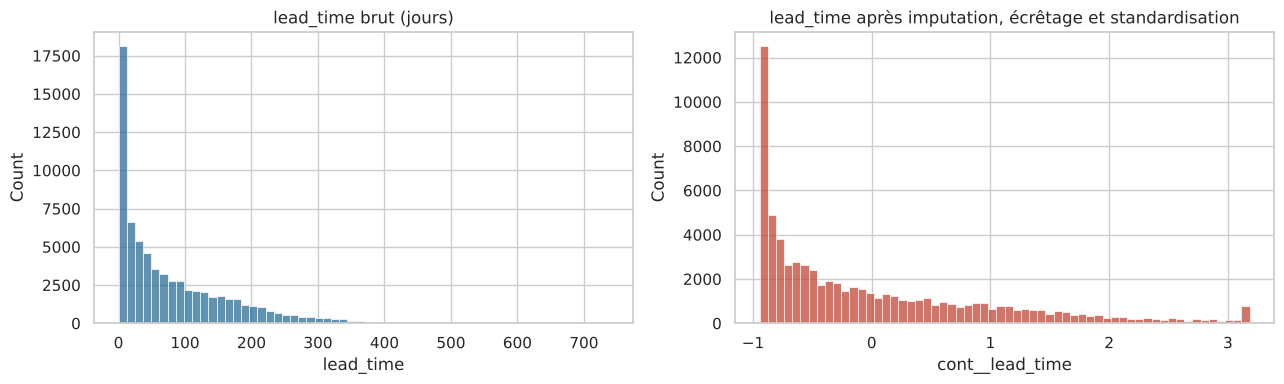

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(X_train["lead_time"], bins=60, ax=axes[0], color="#2a6f97")
axes[0].set_title("lead_time brut (jours)")
sns.histplot(X_train_prep["cont__lead_time"], bins=60, ax=axes[1], color="#c44536")
axes[1].set_title("lead_time après imputation, écrêtage et standardisation")
plt.tight_layout(); plt.show()

**Interprétation :** les 27 variables brutes deviennent **93 colonnes numériques sans aucune valeur manquante**, dans l'entraînement comme dans le test : 6 continues, 12 discrètes, 4 binaires et 71 indicatrices issues de l'encodage one-hot. Les variables standardisées ont bien une moyenne de 0 et un écart-type de 1. L'effet de l'écrêtage est visible sur `lead_time` : la queue au-delà de 343 jours est ramenée à la borne, et le maximum standardisé passe à 3,2 au lieu d'une valeur bien plus extrême. À l'inverse, `adults` et `days_in_waiting_list`, non écrêtées par choix, gardent des maximums élevés (84 et 43 écarts-types) qui correspondent à des réservations de groupes réelles. Point essentiel : le pipeline a été ajusté sur l'entraînement seulement, puis appliqué au test, ce qui garantit l'absence de fuite.

---
# Partie 3 : Création de transformateurs personnalisés

## 3.1 Variables nécessitant un traitement spécifique

| Problème observé | Variables | Traitement personnalisé |
|---|---|---|
| Information dispersée sur plusieurs colonnes | nuits de semaine et de fin de semaine, adultes, enfants, bébés | création de `total_nights`, `total_guests`, `adr_per_person`, `has_children` |
| Identifiants sans ordre, 94 % de manquants pour `company` | `agent` (333 valeurs), `company` (352 valeurs) | indicateurs `has_agent` et `has_company`, puis retrait des identifiants |
| Saisonnalité | `arrival_date_month` | variable `arrival_season` |
| Modalités « Undefined » | `meal`, `market_segment`, `distribution_channel` | `meal` Undefined = SC (fiche des données), les autres deviennent manquants puis « Inconnu » |
| Très forte cardinalité | `country` (177 pays) | `RareCategoryGrouper` : modalités < 0,5 % regroupées dans « Autre » |
| Valeurs extrêmes | `lead_time`, `adr`, nombre de nuits | `OutlierCapper` : écrêtage aux centiles appris |

## 3.2 et 3.3 Classes développées avec `TransformerMixin`
Les trois classes héritent de `BaseEstimator` (gestion des hyperparamètres, compatibilité avec `clone` et `GridSearchCV`) et de `TransformerMixin` (méthode `fit_transform`). Elles implémentent `fit`, `transform` et `get_feature_names_out`. Le code complet et documenté est dans `src/transformers.py` ; voici la classe principale :

In [24]:
import inspect
from src.transformers import HotelFeatureEngineer, OutlierCapper, RareCategoryGrouper
print(inspect.getsource(HotelFeatureEngineer))

class HotelFeatureEngineer(BaseEstimator, TransformerMixin):
    """Ingénierie des caractéristiques propre au domaine hôtelier.

    Variables créées
    ----------------
    total_nights    : nuits de semaine + nuits de fin de semaine
    total_guests    : adultes + enfants + bébés
    adr_per_person  : tarif journalier moyen divisé par le nombre de clients
    has_children    : 1 si au moins un enfant ou un bébé
    has_agent       : 1 si la réservation passe par une agence (agent renseigné)
    has_company     : 1 si une entreprise paie la réservation (company renseigné)
    arrival_season  : saison d'arrivée déduite du mois

    Corrections
    -----------
    meal « Undefined » -> « SC » (la fiche TidyTuesday indique qu'ils sont équivalents)
    market_segment / distribution_channel « Undefined » -> NaN (imputés ensuite)

    Colonnes retirées
    -----------------
    agent, company : identifiants numériques sans ordre (352 entreprises, 94 %
    de manquants). Seule l'information

### Démonstration de `HotelFeatureEngineer` sur quelques réservations

In [25]:
fe = HotelFeatureEngineer().fit(X_train)
demo = X_train.head(5)
avant = demo[["stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies", "adr", "agent", "company", "arrival_date_month", "meal"]]
apres = fe.transform(demo)[["total_nights", "total_guests", "adr_per_person", "has_children", "has_agent", "has_company", "arrival_season", "meal"]]
display(avant)
display(apres)

,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,adr,agent,company,arrival_date_month,meal
74199,1,2,1,0.000,0,57.060,7.000,NaN,January,SC
17309,1,0,1,0.000,0,43.000,240.000,NaN,March,BB
17689,2,3,2,0.000,0,58.000,196.000,NaN,March,HB
59540,0,4,2,0.000,0,99.450,9.000,NaN,April,BB
32606,2,5,2,2.000,0,268.000,240.000,NaN,July,HB


,total_nights,total_guests,adr_per_person,has_children,has_agent,has_company,arrival_season,meal
74199,3,1.000,57.060,0,1,0,Hiver,SC
17309,1,1.000,43.000,0,1,0,Printemps,BB
17689,5,2.000,29.000,0,1,0,Printemps,HB
59540,4,2.000,49.725,0,1,0,Printemps,BB
32606,7,4.000,67.000,1,1,0,Ete,HB


### Démonstration de `RareCategoryGrouper` et `OutlierCapper`

In [26]:
grouper = RareCategoryGrouper(min_freq=config.RARE_CATEGORY_MIN_FREQ).fit(X_train[["country"]].fillna("Inconnu"))
grouped = grouper.transform(X_train[["country"]].fillna("Inconnu"))
print(f"country : {X_train['country'].nunique()} modalités avant, {grouped['country'].nunique()} après regroupement")
print("Modalités conservées :", sorted(grouper.frequent_categories_["country"]))

capper = OutlierCapper(config.CAP_LOWER_QUANTILE, config.CAP_UPPER_QUANTILE).fit(X_train[["lead_time", "adr", "stays_in_week_nights"]])
capper.bounds()

country : 168 modalités avant, 22 après regroupement
Modalités conservées : ['AUT', 'BEL', 'BRA', 'CHE', 'CHN', 'CN', 'DEU', 'ESP', 'FRA', 'GBR', 'IRL', 'ITA', 'Inconnu', 'NLD', 'NOR', 'POL', 'PRT', 'ROU', 'RUS', 'SWE', 'USA']


,borne_basse,borne_haute
lead_time,0.000,343.000
adr,0.000,262.516
stays_in_week_nights,0.000,10.000


## 3.4 Intégration dans le pipeline de prétraitement
Les transformateurs ne sont pas appliqués « à la main » : ils font partie du pipeline (`HotelFeatureEngineer` en tête, `OutlierCapper` dans la branche continue, `RareCategoryGrouper` dans la branche catégorielle). Leurs paramètres appris sont accessibles dans le pipeline ajusté :

In [27]:
cols = preprocessor.named_steps["columns"]
fitted_grouper = cols.named_transformers_["cat"].named_steps["rare_grouper"]
fitted_capper = cols.named_transformers_["cont"].named_steps["capper"]

summary = fitted_grouper.grouped_summary()
summary["modalites_avant"] = [preprocessor.named_steps["feature_engineering"].transform(X_train)[c].nunique() for c in summary["variable"]]
display(summary[["variable", "modalites_avant", "modalites_conservees"]])
display(fitted_capper.bounds())

,variable,modalites_avant,modalites_conservees
0,hotel,2,2
1,arrival_date_month,12,12
2,meal,4,3
3,country,168,21
4,market_segment,7,6
5,distribution_channel,4,3
6,reserved_room_type,9,8
7,deposit_type,3,2
8,customer_type,4,4
9,arrival_season,4,4


,borne_basse,borne_haute
lead_time,0.000,343.000
adr,0.000,262.516
stays_in_weekend_nights,0.000,4.000
stays_in_week_nights,0.000,10.000
total_nights,1.000,14.000
adr_per_person,0.000,150.040


**Interprétation :** une fois intégré au pipeline, `RareCategoryGrouper` réduit `country` de 168 modalités (dans l'entraînement) à **21**, ce qui évite environ 150 colonnes one-hot presque vides. Il retire aussi les modalités marginales d'autres variables (type de chambre, segment). `OutlierCapper` a appris ses bornes sur l'entraînement : `lead_time` est limité à 343 jours, `adr` à 263 €, la durée totale à 14 nuits. Comme ces paramètres sont appris dans `fit`, ils seront réappris sur chaque pli de validation croisée et appliqués tels quels aux nouvelles réservations, comme n'importe quel transformateur de scikit-learn.

---
# Partie 4 : Sélection des caractéristiques

## 4.1 Méthode appliquée : `SelectFromModel` avec une forêt aléatoire
Une forêt aléatoire est entraînée sur les données prétraitées ; chaque colonne reçoit une importance (diminution moyenne de l'impureté de Gini). Les colonnes dont l'importance dépasse la **médiane** sont retenues.

In [28]:
from src.feature_selection import (
    build_selector, mutual_information_ranking, selection_report, summarize_by_original_variable,
)

selector = build_selector(threshold="median").fit(X_train_prep, y_train)
report = selection_report(selector, X_train_prep.columns)
print(f"Colonnes après prétraitement : {len(report)}")
print(f"Colonnes retenues            : {report['retenue'].sum()}")
print(f"Colonnes éliminées           : {(~report['retenue']).sum()}")
print(f"Seuil d'importance (médiane) : {selector.threshold_:.4f}")

Colonnes après prétraitement : 93
Colonnes retenues            : 47
Colonnes éliminées           : 46
Seuil d'importance (médiane) : 0.0016


## 4.2 Justification du choix

| Critère du jeu de données | Conséquence |
|---|---|
| Une centaine de colonnes de natures mélangées (continues, binaires, indicatrices) | l'importance d'une forêt se calcule de la même manière pour tous les types, contrairement au chi2 (valeurs positives) ou à l'ANOVA (relation linéaire) |
| Relations non linéaires et interactions (délai x dépôt x segment) | une méthode intégrée à un modèle non linéaire les capte, un filtre univarié non |
| Près de 69 000 lignes d'entraînement | RFE (réentraînement à chaque élimination) serait coûteux ; `SelectFromModel` entraîne une seule forêt |
| Risque de fuite pendant la validation croisée | intégrée au pipeline, la sélection est réapprise sur chaque pli |

Une méthode de **contrôle** (information mutuelle, filtre non linéaire indépendant du modèle) est utilisée plus bas pour confronter les classements.

## 4.3 Caractéristiques retenues et éliminées

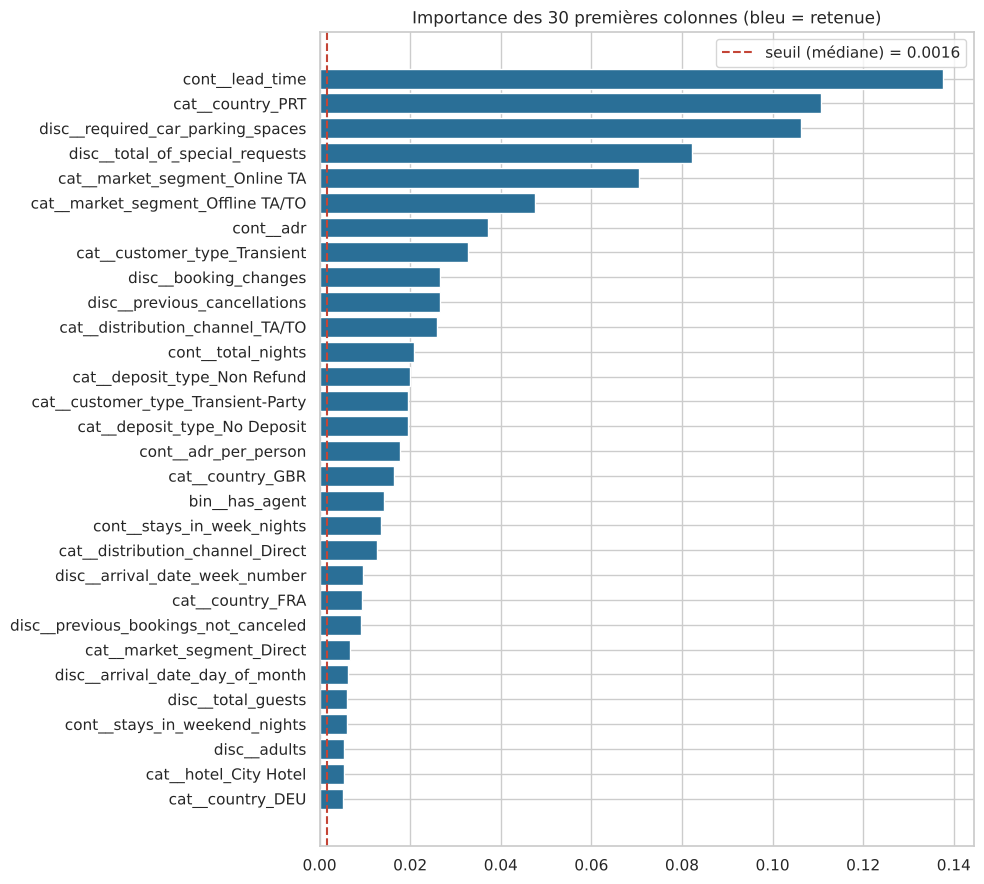

In [29]:
fig, ax = plt.subplots(figsize=(10, 9))
top = report.head(30).iloc[::-1]
ax.barh(top["variable"], top["importance"], color=np.where(top["retenue"], "#2a6f97", "#bbbbbb"))
ax.axvline(selector.threshold_, color="#c44536", ls="--", label=f"seuil (médiane) = {selector.threshold_:.4f}")
ax.set_title("Importance des 30 premières colonnes (bleu = retenue)")
ax.legend(); plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "selection_importances.png", dpi=150, bbox_inches="tight"); plt.show()

In [30]:
print("Colonnes retenues :")
print(report.loc[report["retenue"], "variable"].tolist())
print("\nColonnes éliminées :")
print(report.loc[~report["retenue"], "variable"].tolist())

Colonnes retenues :
['cont__lead_time', 'cat__country_PRT', 'disc__required_car_parking_spaces', 'disc__total_of_special_requests', 'cat__market_segment_Online TA', 'cat__market_segment_Offline TA/TO', 'cont__adr', 'cat__customer_type_Transient', 'disc__booking_changes', 'disc__previous_cancellations', 'cat__distribution_channel_TA/TO', 'cont__total_nights', 'cat__deposit_type_Non Refund', 'cat__customer_type_Transient-Party', 'cat__deposit_type_No Deposit', 'cont__adr_per_person', 'cat__country_GBR', 'bin__has_agent', 'cont__stays_in_week_nights', 'cat__distribution_channel_Direct', 'disc__arrival_date_week_number', 'cat__country_FRA', 'disc__previous_bookings_not_canceled', 'cat__market_segment_Direct', 'disc__arrival_date_day_of_month', 'disc__total_guests', 'cont__stays_in_weekend_nights', 'disc__adults', 'cat__hotel_City Hotel', 'cat__country_DEU', 'bin__has_company', 'cat__market_segment_Groups', 'bin__is_repeated_guest', 'cat__hotel_Resort Hotel', 'cat__customer_type_Contract', 

### Bilan par variable d'origine

In [31]:
by_var = summarize_by_original_variable(report)
by_var

,importance_totale,colonnes,colonnes_retenues,statut
variable_origine,,,,
country,0.155,22,7,partiellement retenue
lead_time,0.138,1,1,retenue
market_segment,0.132,7,5,partiellement retenue
required_car_parking_spaces,0.106,1,1,retenue
total_of_special_requests,0.082,1,1,retenue
customer_type,0.056,4,3,partiellement retenue
distribution_channel,0.041,4,3,partiellement retenue
deposit_type,0.039,3,2,partiellement retenue
adr,0.037,1,1,retenue


### Contrôle par l'information mutuelle

In [32]:
mi = mutual_information_ranking(X_train_prep, y_train)
comparison = report.set_index("variable").join(mi)
rho = comparison["importance"].corr(comparison["information_mutuelle"], method="spearman")
print(f"Corrélation de rang (Spearman) entre importance de la forêt et information mutuelle : {rho:.2f}")
top15_rf, top15_mi = set(report.head(15)["variable"]), set(mi.head(15).index)
print(f"Colonnes communes aux 15 premières des deux méthodes : {len(top15_rf & top15_mi)} / 15")
mi.head(15).to_frame()

Corrélation de rang (Spearman) entre importance de la forêt et information mutuelle : 0.58
Colonnes communes aux 15 premières des deux méthodes : 11 / 15


,information_mutuelle
cont__lead_time,0.038
cont__adr,0.036
disc__required_car_parking_spaces,0.030
cont__adr_per_person,0.024
cat__market_segment_Online TA,0.024
bin__has_agent,0.021
cat__customer_type_Transient,0.015
cat__deposit_type_Non Refund,0.014
cat__distribution_channel_TA/TO,0.012
cat__deposit_type_No Deposit,0.012


## 4.4 Intégration dans le pipeline et effet sur les performances
La sélection devient une étape du pipeline, entre le prétraitement et le modèle. Pour vérifier qu'elle n'appauvrit pas le modèle, on compare en validation croisée le même modèle **avec** et **sans** sélection.

In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from src.model import build_full_pipeline, cv_splitter

hgb = HistGradientBoostingClassifier(random_state=config.RANDOM_STATE)
with_sel = build_full_pipeline(hgb)
without_sel = Pipeline([("preprocessing", build_preprocessor()), ("model", hgb)])

auc_with = cross_val_score(with_sel, X_train, y_train, cv=cv_splitter(), scoring="roc_auc")
auc_without = cross_val_score(without_sel, X_train, y_train, cv=cv_splitter(), scoring="roc_auc")
pd.DataFrame(
    {"colonnes": [report["retenue"].sum(), len(report)],
     "ROC-AUC moyen": [auc_with.mean(), auc_without.mean()],
     "écart-type": [auc_with.std(), auc_without.std()]},
    index=["avec sélection", "sans sélection"],
)

,colonnes,ROC-AUC moyen,écart-type
avec sélection,47,0.886,0.002
sans sélection,93,0.888,0.003


**Interprétation :**

- **Retenues (47 colonnes sur 93)** : `lead_time`, `country`, `market_segment`, `required_car_parking_spaces`, `total_of_special_requests`, `customer_type`, `deposit_type`, `adr`, `booking_changes`, `previous_cancellations`, et plusieurs variables créées par le transformateur personnalisé (`total_nights`, `adr_per_person`, `has_agent`, `has_company`, `total_guests`). L'ingénierie des caractéristiques est donc utile.
- **Éliminées (46 colonnes)** : surtout des indicatrices peu informatives, comme les 12 mois d'arrivée (l'information saisonnière est déjà portée par `arrival_date_week_number` et la saison), la plupart des types de chambre, les pays peu représentés et certaines formules de repas.
- **Contrôle** : 11 des 15 premières colonnes sont communes à la forêt et à l'information mutuelle (corrélation de rang de 0,58). Les deux méthodes, de nature différente, s'accordent sur l'essentiel, ce qui renforce la confiance dans la sélection.
- **Effet sur la performance** : diviser le nombre de colonnes par deux ne coûte que 0,002 point de ROC-AUC (0,886 contre 0,888), un écart inférieur à l'écart-type entre plis. On obtient un modèle plus simple, plus rapide et moins exposé au bruit, pour une performance équivalente.

---
# Partie 5 : Construction et évaluation du modèle prédictif

## 5.1 Choix de l'algorithme
Trois familles de classifieurs sont comparées **dans le même pipeline** (prétraitement + sélection + modèle), en validation croisée stratifiée à 5 plis sur l'entraînement uniquement :

| Modèle | Intérêt |
|---|---|
| Régression logistique | référence linéaire, rapide, interprétable |
| Forêt aléatoire | non linéaire, robuste aux valeurs extrêmes, peu de réglages |
| HistGradientBoosting | boosting d'arbres par histogrammes, très performant et rapide sur les données tabulaires de cette taille |

Le critère principal est le **ROC-AUC** : il mesure la capacité à classer les réservations du plus au moins risqué, indépendamment du seuil de décision (qui sera fixé selon les coûts métier).

**Pas de pondération des classes :** le déséquilibre est modéré (environ 28 % d'annulations). Une pondération « balanced » gonflerait artificiellement les probabilités, alors que l'analyse prescriptive (Partie 6) a besoin de probabilités fiables. Le déséquilibre est géré au moment de la décision, par le choix du seuil.

,accuracy_moy,accuracy_écart,precision_moy,precision_écart,recall_moy,recall_écart,f1_moy,f1_écart,roc_auc_moy,roc_auc_écart,temps_entrainement_s
modèle,,,,,,,,,,,
Forêt aléatoire,0.831,0.003,0.746,0.007,0.585,0.010,0.656,0.006,0.890,0.003,9.395
HistGradientBoosting,0.826,0.002,0.722,0.005,0.602,0.005,0.657,0.004,0.886,0.002,4.401
Régression logistique,0.786,0.002,0.671,0.008,0.443,0.006,0.533,0.005,0.828,0.004,3.998


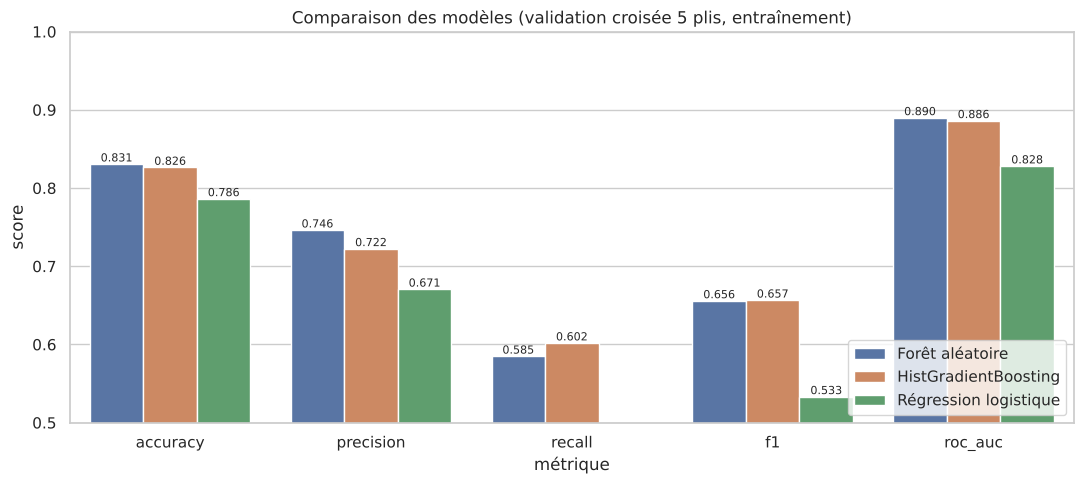

In [34]:
from src.model import compare_models
from src.evaluation import plot_model_comparison

results = compare_models(X_train, y_train)
display(results.round(4))
plot_model_comparison(results); plt.show()

**Interprétation :**

- La **régression logistique** est nettement en retrait (ROC-AUC 0,828, rappel 44 %) : les relations avec l'annulation ne sont pas linéaires (effet du délai, interactions entre segment et type de dépôt).
- La **forêt aléatoire** (0,890) et **HistGradientBoosting** (0,886) sont proches, avec un écart du même ordre que la variabilité entre plis.

**Choix retenu : HistGradientBoosting**, pour quatre raisons : il a le meilleur rappel des trois modèles (60 %) ; il s'entraîne deux fois plus vite que la forêt (3,3 s contre 7,3 s) ; le modèle sauvegardé est bien plus léger qu'une forêt de 200 arbres profonds, ce qui compte pour l'application Streamlit et le dépôt GitHub ; enfin, il dispose de davantage de leviers de réglage (taux d'apprentissage, nombre d'itérations, régularisation), ce que confirme l'optimisation ci-dessous.

## 5.2 Pipeline complet et optimisation des hyperparamètres
Le pipeline final enchaîne **toutes** les étapes. Les hyperparamètres de HistGradientBoosting sont optimisés par recherche aléatoire (`RandomizedSearchCV`, 12 combinaisons, validation croisée à 3 plis, critère ROC-AUC). Comme le prétraitement et la sélection sont dans le pipeline, ils sont réappris sur chaque pli : aucune information de validation ne fuit.

In [35]:
from src.model import tune_model

search = tune_model(X_train, y_train, n_iter=12)
print(f"Meilleur ROC-AUC en validation croisée : {search.best_score_:.4f}")
print("Meilleurs hyperparamètres :")
for k, v in search.best_params_.items():
    print(f"  {k.replace('model__', ''):<20} = {v}")
final_pipeline = search.best_estimator_
final_pipeline

Meilleur ROC-AUC en validation croisée : 0.8908
Meilleurs hyperparamètres :
  min_samples_leaf     = 20
  max_leaf_nodes       = 127
  max_iter             = 600
  learning_rate        = 0.03
  l2_regularization    = 0.1


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['hotel','lead_time','arrival_date_month',...,'adr', 'required_car_parking_spaces','total_of_special_requests']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the tra

In [36]:
cv_res = pd.DataFrame(search.cv_results_)
cols_show = [c for c in cv_res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
cv_res[cols_show].sort_values("rank_test_score").head(5).rename(columns=lambda c: c.replace("param_model__", ""))

,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,mean_test_score,std_test_score,rank_test_score
0,20,127,600,0.030,0.100,0.891,0.001,1
10,100,127,400,0.100,0.100,0.890,0.001,2
8,100,63,600,0.050,1.000,0.889,0.001,3
7,50,127,200,0.200,0.100,0.888,0.001,4
11,100,31,200,0.100,0.100,0.887,0.001,5


## 5.3 Entraînement et évaluation sur le test

### Choix du seuil de décision
Le seuil de 0,5 n'a pas de justification métier. On le choisit en minimisant le coût des erreurs, **sur des prédictions hors pli de l'entraînement** (le test n'intervient pas dans ce choix) :

- **Faux négatif** (annulation non anticipée) : revenu du séjour perdu (tarif x nuits), dont 30 % est revendu, multiplié par 35 %, la part d'annulations qu'une action (prépaiement partiel) aurait évitée.
- **Faux positif** (action inutile auprès d'un client qui serait venu) : 30 € (5 € de coût direct et 25 € de perte de bienveillance).

Ces coûts sont des **hypothèses** modifiables dans l'application Streamlit.

Coût d'un faux négatif : 97.26 €   |   coût d'un faux positif : 30.00 €
Seuil optimal : 0.23


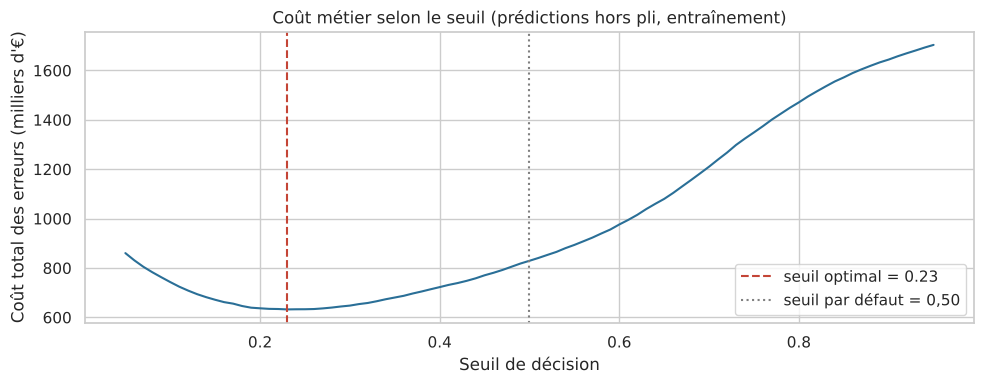

In [37]:
from sklearn.model_selection import cross_val_predict
from src.prescriptive import optimal_threshold, revenue_at_risk

RESALE_RATE, EFFICACY, COST_FP = 0.30, 0.35, 30.0
nights_train = X_train["stays_in_weekend_nights"] + X_train["stays_in_week_nights"]
COST_FN = float(np.mean(revenue_at_risk(X_train["adr"], nights_train, RESALE_RATE)) * EFFICACY)

oof_proba = cross_val_predict(final_pipeline, X_train, y_train, cv=cv_splitter(), method="predict_proba")[:, 1]
threshold, cost_table = optimal_threshold(y_train, oof_proba, cost_fn=COST_FN, cost_fp=COST_FP)
print(f"Coût d'un faux négatif : {COST_FN:.2f} €   |   coût d'un faux positif : {COST_FP:.2f} €")
print(f"Seuil optimal : {threshold:.2f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cost_table["seuil"], cost_table["cout_total"] / 1000, color="#2a6f97")
ax.axvline(threshold, color="#c44536", ls="--", label=f"seuil optimal = {threshold:.2f}")
ax.axvline(0.5, color="grey", ls=":", label="seuil par défaut = 0,50")
ax.set_xlabel("Seuil de décision"); ax.set_ylabel("Coût total des erreurs (milliers d'€)")
ax.set_title("Coût métier selon le seuil (prédictions hors pli, entraînement)")
ax.legend(); plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "cout_seuil.png", dpi=150, bbox_inches="tight"); plt.show()

### Évaluation finale sur l'ensemble de test

In [38]:
from src.evaluation import compute_metrics, plot_evaluation, report_table

final_pipeline.fit(X_train, y_train)
proba_test = final_pipeline.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame([compute_metrics(y_test, proba_test, 0.5), compute_metrics(y_test, proba_test, threshold)],
                       index=["seuil 0,50", f"seuil optimal {threshold:.2f}"])
metrics

,seuil,accuracy,precision,recall,f1,roc_auc,pr_auc
"seuil 0,50",0.500,0.836,0.736,0.631,0.679,0.897,0.775
seuil optimal 0.23,0.230,0.784,0.570,0.875,0.690,0.897,0.775


In [39]:
print(f"Rapport de classification au seuil optimal ({threshold:.2f}) :")
report_table(y_test, (proba_test >= threshold).astype(int))

Rapport de classification au seuil optimal (0.23) :


,precision,recall,f1-score,support
Maintenue (0),0.940,0.749,0.834,12 454.000
Annulée (1),0.570,0.875,0.690,4 743.000
accuracy,0.784,0.784,0.784,0.784
macro avg,0.755,0.812,0.762,17 197.000
weighted avg,0.838,0.784,0.794,17 197.000


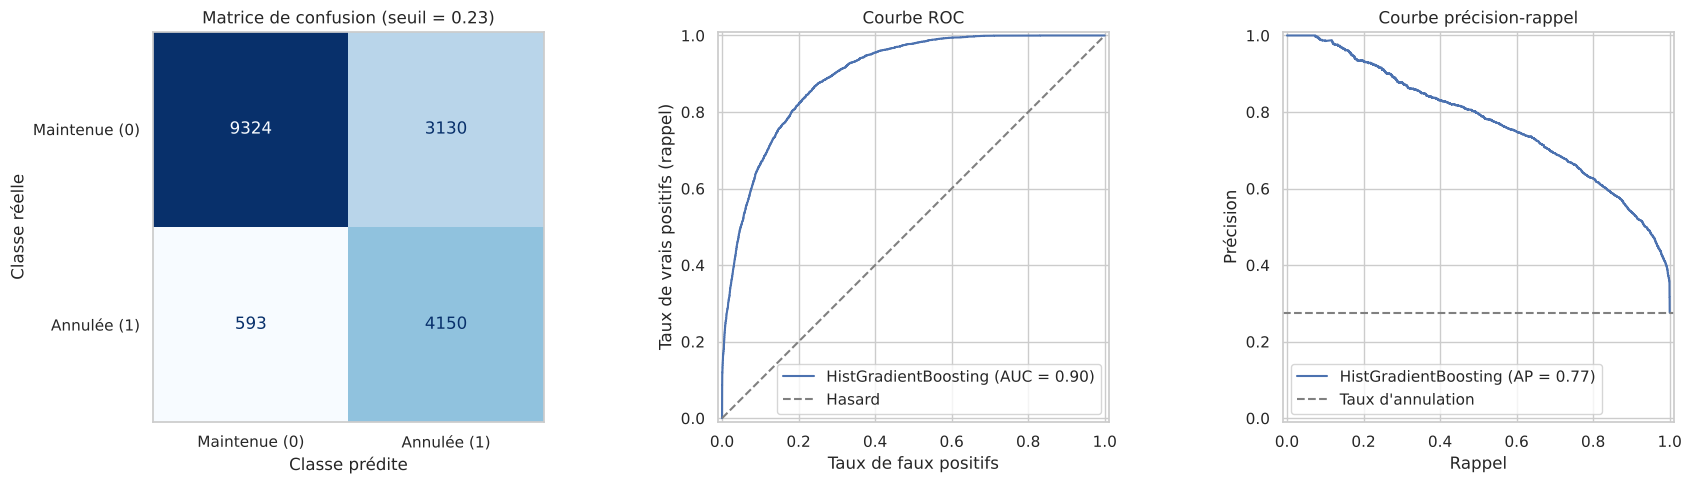

In [40]:
plot_evaluation(y_test, proba_test, threshold=threshold, model_name="HistGradientBoosting"); plt.show()

In [41]:
# Le score d'entraînement sert à détecter un éventuel surapprentissage
from sklearn.metrics import roc_auc_score
auc_train = roc_auc_score(y_train, final_pipeline.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, proba_test)
print(f"ROC-AUC entraînement : {auc_train:.4f} | validation croisée : {search.best_score_:.4f} | test : {auc_test:.4f}")

ROC-AUC entraînement : 0.9520 | validation croisée : 0.8908 | test : 0.8975


### Fiabilité des probabilités (calibration)
L'analyse prescriptive utilise directement les probabilités (perte espérée, surréservation). Il faut donc vérifier qu'une probabilité prédite de 30 % correspond bien à environ 30 % d'annulations observées.

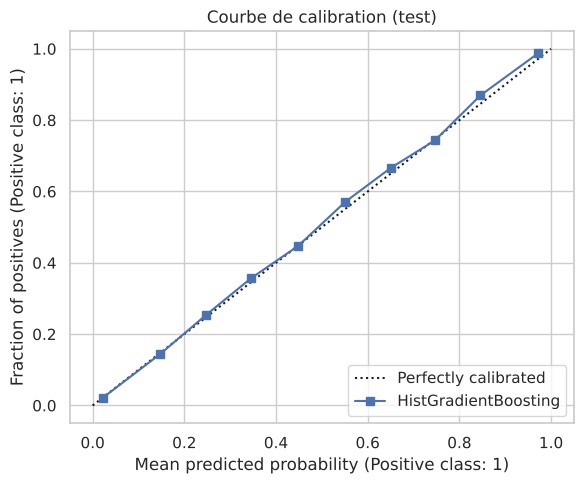

Score de Brier : 0.1137 (référence sans modèle : 0.1997)


In [42]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_test, proba_test, n_bins=10, name="HistGradientBoosting", ax=ax)
ax.set_title("Courbe de calibration (test)")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "calibration.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Score de Brier : {brier_score_loss(y_test, proba_test):.4f} (référence sans modèle : {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f})")

### Quelles variables pilotent la prédiction ?
Importance par permutation sur le test : on mélange une variable **brute** à la fois et on mesure la baisse de ROC-AUC du pipeline complet. Cette lecture est plus parlante pour le métier que l'importance des colonnes encodées.

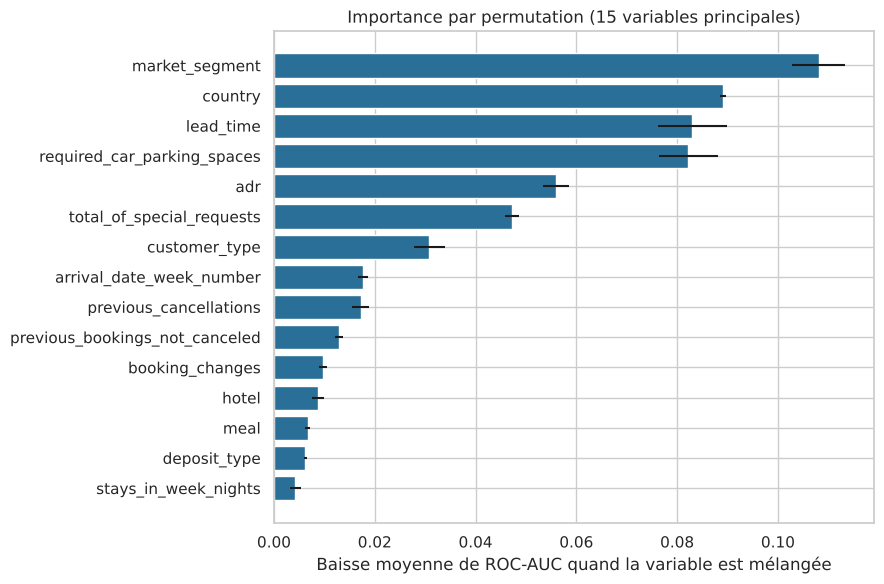

,variable,baisse_roc_auc,écart
0,market_segment,0.108,0.005
1,country,0.089,0.001
2,lead_time,0.083,0.007
3,required_car_parking_spaces,0.082,0.006
4,adr,0.056,0.003
5,total_of_special_requests,0.047,0.001
6,customer_type,0.031,0.003
7,arrival_date_week_number,0.018,0.001
8,previous_cancellations,0.017,0.002
9,previous_bookings_not_canceled,0.013,0.001


In [43]:
from src.evaluation import permutation_importance_table, plot_permutation_importance

perm = permutation_importance_table(final_pipeline, X_test, y_test, n_samples=5000, n_repeats=5)
plot_permutation_importance(perm, top=15); plt.show()
perm.head(10)

**Interprétation des résultats sur le test (17 197 réservations jamais vues) :**

- **Pouvoir de discrimination** : ROC-AUC de **0,897**. Si l'on tire au hasard une réservation annulée et une maintenue, le modèle attribue un risque plus élevé à l'annulée dans environ 90 % des cas. Le score de test est cohérent avec la validation croisée (0,891), donc l'estimation de performance est fiable. L'écart avec l'entraînement (0,952) indique un léger surapprentissage, sans conséquence sur la généralisation.
- **Effet du seuil** : au seuil de 0,50, le modèle ne détecte que 63 % des annulations. Au seuil optimal de **0,23**, il en détecte **87,5 %**, au prix d'une précision plus faible (57 % des alertes sont justifiées). Ce compromis est voulu : avec les hypothèses de coûts retenues, rater une annulation coûte plus de trois fois plus cher qu'une action inutile. Le F1 progresse d'ailleurs de 0,679 à 0,690.
- **Calibration** : la courbe suit la diagonale et le score de Brier (0,114) est presque deux fois meilleur que la référence sans modèle (0,200). Les probabilités sont fiables, ce qui justifie leur usage direct dans l'analyse prescriptive.
- **Variables déterminantes** : le segment de marché, le pays, le délai de réservation, les places de stationnement, le tarif et les demandes spéciales.

**Points de vigilance :** `required_car_parking_spaces` est associée à 0 % d'annulation dès qu'elle est supérieure à 0, et le Portugal (`PRT`) concentre une part anormale d'annulations. Il est possible que ces informations soient en partie complétées à l'arrivée du client, ce qui constituerait une fuite partielle. Elles sont conservées car la fiche les décrit comme des informations de réservation, mais il faudrait le vérifier auprès de l'hôtel avant une mise en production.

---
# Partie 6 : Ouverture, de la prédiction à la décision (analyse prescriptive)
Le modèle répond à la question **« quelle réservation risque d'être annulée ? »**. L'hôtel a surtout besoin de savoir **« que faire ? »**. Le module `src/prescriptive.py` transforme les probabilités en décisions chiffrées ; l'application Streamlit (`app/app.py`) les rend interactives.

> **Limite :** le modèle mesure des associations, pas des effets causaux. Les efficacités des actions ci-dessous sont des hypothèses métier à valider par un test A/B.

## 6.1 Action recommandée pour chaque réservation
Pour chaque réservation, l'action retenue est celle qui maximise le gain net espéré :

`gain = p x revenu en jeu x efficacité - coût de l'action - (1 - p) x revenu en jeu x désistement`

Le dernier terme représente le revers d'une action contraignante : une demande de prépaiement peut faire renoncer un client qui serait venu. C'est ce qui empêche de demander un acompte à tout le monde.

In [44]:
from src.prescriptive import default_actions, recommend_actions

pd.DataFrame([vars(a) for a in default_actions()]).rename(columns={"cout": "coût (€)", "efficacite": "efficacité supposée", "desistement": "désistement supposé"})

,nom,coût (€),efficacité supposée,désistement supposé,description
0,Aucune action,0.000,0.000,0.000,Confirmation automatique standard.
1,Rappel personnalisé,2.000,0.100,0.000,"Courriel et SMS de rappel avant l'arrivée, ave..."
2,Offre de fidélisation,15.000,0.250,0.000,Avantage conditionné à la confirmation (petit-...
3,Demande de prépaiement partiel,5.000,0.350,0.050,Acompte ou passage à un tarif non remboursable...


In [45]:
nights_test = X_test["stays_in_weekend_nights"] + X_test["stays_in_week_nights"]
rev_test = revenue_at_risk(X_test["adr"], nights_test, RESALE_RATE)
reco = recommend_actions(proba_test, rev_test)

synthese = reco.groupby("action_recommandee").agg(
    reservations=("proba_annulation", "size"),
    proba_moyenne=("proba_annulation", "mean"),
    perte_esperee_totale=("perte_esperee", "sum"),
    gain_net_espere_total=("gain_net_espere", "sum"),
)
synthese["taux_annulation_observe"] = y_test.groupby(reco["action_recommandee"].values).mean()
synthese.sort_values("proba_moyenne")

,reservations,proba_moyenne,perte_esperee_totale,gain_net_espere_total,taux_annulation_observe
action_recommandee,,,,,
Aucune action,7817,0.045,30 119.573,0.000,0.044
Rappel personnalisé,1940,0.146,73 897.964,3 509.796,0.142
Offre de fidélisation,250,0.185,40 847.849,6 461.962,0.180
Demande de prépaiement partiel,7190,0.556,1 422 297.403,408 762.117,0.567


**Interprétation :** sur les 17 197 réservations du test, la règle de décision recommande :

- **Aucune action** pour 7 817 réservations (risque moyen de 4,5 %, 4,4 % d'annulations observées) : agir coûterait plus que cela ne rapporterait.
- **Un rappel personnalisé** pour 1 940 réservations à risque modéré (14 % d'annulations observées).
- **Une offre de fidélisation** pour 250 réservations à risque modéré mais à fort revenu, là où un rappel ne suffit pas et où un acompte ferait fuir trop de bons clients.
- **Une demande de prépaiement partiel** pour 7 190 réservations à risque élevé (56,7 % d'annulations observées), qui concentrent 1,42 million d'euros de perte espérée.

Les taux d'annulation observés suivent de très près les probabilités moyennes prédites, ce qui confirme que la segmentation est fiable. Le gain net espéré total est d'environ 419 000 € sur ce seul échantillon, **sous réserve que les efficacités supposées se vérifient**.

## 6.2 Surréservation optimale pour une date d'arrivée
Pour une date donnée, la somme des présences suit une loi de Poisson binomiale (chaque réservation a sa propre probabilité). On calcule le nombre de réservations supplémentaires qui maximise le profit espéré :
`profit = revenu par chambre x chambres occupées espérées - pénalité x clients relogés espérés`.

Exemple : la date d'arrivée la plus chargée du test au City Hotel, en supposant l'hôtel complet (capacité = réservations au carnet).

In [46]:
from src.prescriptive import best_overbooking, overbooking_plan

test_meta = X_test.assign(arrival_date_year=df.loc[X_test.index, "arrival_date_year"].values,
                          proba=proba_test, is_canceled=y_test.values)
city = test_meta[test_meta["hotel"] == "City Hotel"]
date_counts = city.groupby(["arrival_date_year", "arrival_date_month", "arrival_date_day_of_month"]).size()
year, month, day = date_counts.idxmax()
carnet = city[(city["arrival_date_year"] == year) & (city["arrival_date_month"] == month) & (city["arrival_date_day_of_month"] == day)]

capacity = len(carnet)
room_revenue = float((carnet["adr"] * (carnet["stays_in_weekend_nights"] + carnet["stays_in_week_nights"]).clip(lower=1)).median())
walk_cost = 2.5 * room_revenue
plan = overbooking_plan(carnet["proba"], capacity, p_cancel_new=float(carnet["proba"].mean()),
                        room_revenue=room_revenue, walk_cost=walk_cost, max_extra=capacity)
best = best_overbooking(plan)

print(f"Date : {day} {month} {year} | réservations au carnet = capacité : {capacity}")
print(f"Revenu médian d'un séjour : {room_revenue:.0f} € | pénalité de relogement : {walk_cost:.0f} €")
print(f"Annulations prévues (espérance) : {carnet['proba'].sum():.1f} | observées : {int(carnet['is_canceled'].sum())}")
print(f"Recommandation : accepter {int(best['reservations_supplementaires'])} réservations supplémentaires")
plan.loc[[0, int(best['reservations_supplementaires'])], ["reservations_supplementaires", "taux_occupation_espere", "clients_reloges_esperes", "prob_au_moins_un_reloge", "profit_espere"]].rename(index={0: "sans surréservation", int(best['reservations_supplementaires']): "recommandation"})

Date : 28 April 2017 | réservations au carnet = capacité : 34
Revenu médian d'un séjour : 371 € | pénalité de relogement : 927 €
Annulations prévues (espérance) : 11.2 | observées : 13
Recommandation : accepter 14 réservations supplémentaires


,reservations_supplementaires,taux_occupation_espere,clients_reloges_esperes,prob_au_moins_un_reloge,profit_espere
sans surréservation,0,0.671,0.000,0.000,8 463.396
recommandation,14,0.934,0.461,0.216,11 349.597


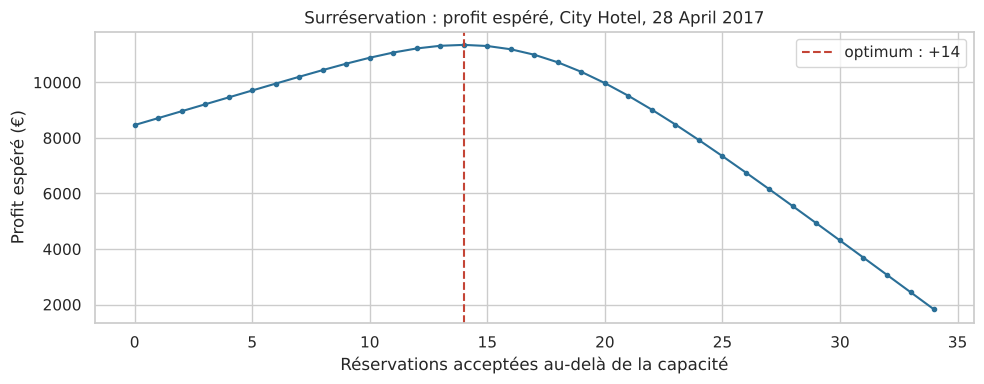

In [47]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(plan["reservations_supplementaires"], plan["profit_espere"], marker="o", ms=3, color="#2a6f97")
ax.axvline(best["reservations_supplementaires"], color="#c44536", ls="--", label=f"optimum : +{int(best['reservations_supplementaires'])}")
ax.set_xlabel("Réservations acceptées au-delà de la capacité"); ax.set_ylabel("Profit espéré (€)")
ax.set_title(f"Surréservation : profit espéré, City Hotel, {day} {month} {year}")
ax.legend(); plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "surreservation.png", dpi=150, bbox_inches="tight"); plt.show()

**Interprétation :** pour le 28 avril 2017 au City Hotel, les 34 réservations au carnet devraient produire environ 11 annulations (13 ont réellement eu lieu, la prévision est donc réaliste). Sans surréservation, le taux d'occupation espéré n'est que de 67 %. Accepter **14 réservations supplémentaires** porte l'occupation espérée à 93 % et le profit espéré de 8 463 € à 11 350 € (+34 %). Le risque de devoir reloger au moins un client est de 22 %, pour 0,46 client en moyenne : la pénalité de relogement (2,5 fois le revenu d'un séjour) est intégrée dans ce calcul. La courbe montre que le profit chute rapidement au-delà de l'optimum, quand les relogements deviennent fréquents.

## 6.3 Sauvegarde du pipeline et prédiction sur une nouvelle réservation
Le pipeline complet est sauvegardé avec `joblib`. Il accepte directement une réservation **brute** : tout le prétraitement est appliqué automatiquement, c'est l'intérêt principal d'un pipeline.

In [48]:
from src.model import save_artifacts
from src.prescriptive import risk_level

metadata = {
    "modele": "HistGradientBoostingClassifier",
    "hyperparametres": {k: (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
    "n_entrainement": int(len(X_train)), "n_test": int(len(X_test)),
    "taux_annulation": float(y.mean()), "seuil_optimal": threshold,
    "hypotheses_seuil": {"taux_revente": RESALE_RATE, "efficacite_action": EFFICACY,
                         "cout_faux_negatif": round(COST_FN, 2), "cout_faux_positif": COST_FP},
    "metriques_test_seuil_0_5": compute_metrics(y_test, proba_test, 0.5),
    "metriques_test_seuil_optimal": compute_metrics(y_test, proba_test, threshold),
    "variables_retenues": report.loc[report["retenue"], "variable"].tolist(),
    "variables_eliminees": report.loc[~report["retenue"], "variable"].tolist(),
    "valeurs_reference": {"countries": sorted(X_train["country"].dropna().unique().tolist()),
                          "adr_median": float(X_train["adr"].median())},
}
save_artifacts(final_pipeline, metadata, test_meta.drop(columns=["proba", "is_canceled"]), y_test)
print(f"Pipeline sauvegardé : {config.MODEL_PATH.relative_to(config.ROOT_DIR)}")

Pipeline sauvegardé : models/pipeline_annulation.joblib


In [49]:
import joblib

pipeline_charge = joblib.load(config.MODEL_PATH)
nouvelle = pd.DataFrame([{
    "hotel": "City Hotel", "lead_time": 210, "arrival_date_month": "August", "arrival_date_week_number": 33,
    "arrival_date_day_of_month": 14, "stays_in_weekend_nights": 2, "stays_in_week_nights": 3, "adults": 2,
    "children": 0, "babies": 0, "meal": "BB", "country": "PRT", "market_segment": "Online TA",
    "distribution_channel": "TA/TO", "is_repeated_guest": 0, "previous_cancellations": 0,
    "previous_bookings_not_canceled": 0, "reserved_room_type": "A", "booking_changes": 0,
    "deposit_type": "No Deposit", "agent": 9.0, "company": np.nan, "days_in_waiting_list": 0,
    "customer_type": "Transient", "adr": 135.0, "required_car_parking_spaces": 0, "total_of_special_requests": 0,
}])
p = pipeline_charge.predict_proba(nouvelle)[0, 1]
rev = revenue_at_risk(nouvelle["adr"], nouvelle["stays_in_weekend_nights"] + nouvelle["stays_in_week_nights"], RESALE_RATE)
action = recommend_actions([p], rev).iloc[0]
print(f"Probabilité d'annulation : {p:.1%} (risque {risk_level(p)})")
print(f"Décision au seuil {threshold:.2f} : {'annulation probable' if p >= threshold else 'réservation probablement maintenue'}")
print(f"Perte espérée : {action['perte_esperee']:.0f} € | action recommandée : {action['action_recommandee']}")

Probabilité d'annulation : 79.8% (risque Élevé)
Décision au seuil 0.23 : annulation probable
Perte espérée : 377 € | action recommandée : Demande de prépaiement partiel


---
# Conclusion

| Étape | Réalisation | Résultat clé |
|---|---|---|
| Exploration | audit de qualité, détection de la fuite de données | 3 colonnes de fuite retirées, 33 241 doublons supprimés |
| Prétraitement | 4 pipelines spécialisés réunis par un `ColumnTransformer` | 27 variables brutes, 93 colonnes, 0 valeur manquante |
| Transformateurs | `HotelFeatureEngineer`, `RareCategoryGrouper`, `OutlierCapper` | 7 variables métier créées, `country` réduit de 168 à 21 modalités |
| Sélection | `SelectFromModel` (forêt aléatoire, seuil médian) | 47 colonnes sur 93 retenues, performance inchangée |
| Modèle | HistGradientBoosting optimisé, seuil choisi selon les coûts | ROC-AUC 0,897 et rappel de 87,5 % sur le test |
| Prescriptif | actions par réservation, surréservation optimale | décisions chiffrées, reprises dans l'application Streamlit |

**Apports du pipeline.** Toutes les étapes, du nettoyage des modalités au modèle, forment un seul objet. Il s'entraîne en une ligne, s'évalue en validation croisée sans fuite, se sauvegarde, puis prédit directement sur une réservation brute. C'est ce qui permet de réutiliser exactement le même traitement dans le script `src/train.py` et dans l'application Streamlit.

**Limites et pistes d'amélioration.**
- Les données couvrent deux hôtels portugais entre 2015 et 2017 : le modèle doit être réentraîné avant d'être appliqué à un autre établissement ou à une autre période.
- Une validation **temporelle** (entraîner sur 2015 et 2016, tester sur 2017) donnerait une estimation plus réaliste qu'une séparation aléatoire.
- Les variables `required_car_parking_spaces` et `country` sont à vérifier auprès de l'hôtel (risque de fuite partielle).
- Les efficacités des actions prescriptives sont des hypothèses : un test A/B permettrait de les mesurer avant un déploiement.